# PRAKTIKUM DATA MINING: DATA PREPROCESSING
Notebook ini berisi tahapan lengkap pra-pemrosesan data: cek record, missing values, visualisasi heatmap, cek data duplikat, dan deteksi outlier.

### 1. Import Library
Memanggil library pandas, numpy, matplotlib, dan seaborn untuk manipulasi dan visualisasi data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Load Dataset & Preview Data
Membaca file data transaksi `market_basket_dataset.csv` dan menampilkan 5 baris pertama.

In [2]:
df = pd.read_csv('market_basket_dataset.csv', header=None)
display(df.head())

,0,1,2,3,4,5,6,7,8,9
0,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
1,Milk,NaN,Butter,NaN,Eggs,Juice,Chips,Soda,NaN,Apples
2,NaN,NaN,Butter,NaN,NaN,Juice,Chips,NaN,NaN,Apples
3,Milk,NaN,NaN,NaN,NaN,Juice,NaN,Soda,NaN,Apples
4,NaN,NaN,Butter,NaN,Eggs,Juice,NaN,Soda,Chicken,NaN


### 3. Cek Dimensi & Jumlah Data Record
Mengetahui jumlah baris (record transaksi) dan kolom (item slot belanjaan).

In [3]:
print("Dimensi dataset (baris, kolom):", df.shape)
print("Jumlah total record awal:", len(df))

Dimensi dataset (baris, kolom): (1501, 10)
Jumlah total record awal: 1501


### 4. Pengecekan Missing Values (Nilai Kosong)
Mengecek jumlah nilai NaN per kolom dan total keseluruhan pada data transaksi.

In [4]:
print("Jumlah Missing Value per kolom:")
print(df.isnull().sum())
print("-" * 40)
print("Total Missing Value seluruh data:", df.isnull().sum().sum())

Jumlah Missing Value per kolom:
0    865
1    878
2    853
3    877
4    857
5    864
6    843
7    866
8    894
9    873
----------------------------------------
Total Missing Value seluruh data: 8670


### 5. Visualisasi Heatmap Missing Values
Menampilkan peta sebaran missing values secara visual menggunakan gradasi warna.

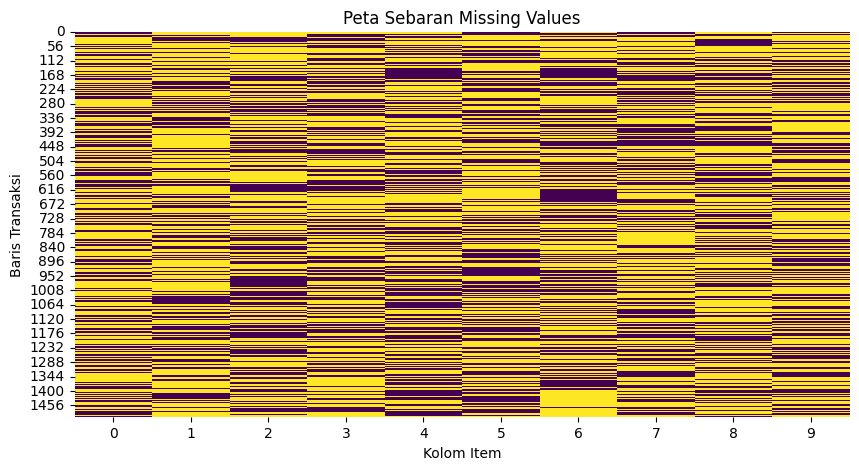

In [5]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Peta Sebaran Missing Values')
plt.xlabel('Kolom Item')
plt.ylabel('Baris Transaksi')
plt.show()

### 6. Pengecekan & Pembersihan Data Duplikat
Mengecek transaksi kembar dan membersihkannya dengan drop_duplicates.

In [6]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah data duplikat:", jumlah_duplikat)

df_clean = df.drop_duplicates()
print("Jumlah record awal:", len(df))
print("Jumlah record setelah hapus duplikat:", len(df_clean))

Jumlah data duplikat: 774
Jumlah record awal: 1501
Jumlah record setelah hapus duplikat: 727


### 7. Pengecekan Outlier (Boxplot & Transaksi Kosong)
Mendeteksi anomali pada panjang keranjang belanja dan mengecek apakah ada transaksi kosong (0 item).

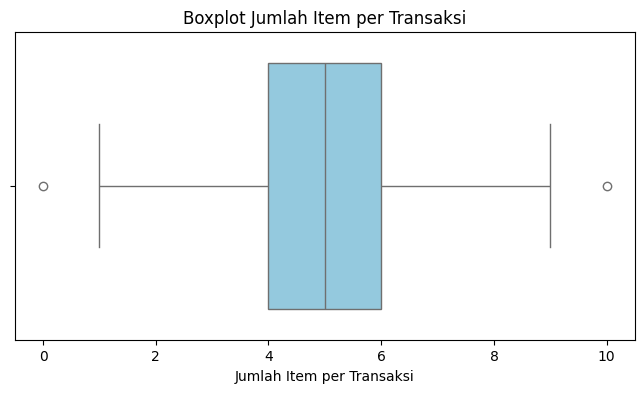

Jumlah transaksi kosong (0 item): 1


In [7]:
item_per_transaksi = df_clean.notnull().sum(axis=1)

plt.figure(figsize=(8, 4))
sns.boxplot(x=item_per_transaksi, color="skyblue")
plt.title("Boxplot Jumlah Item per Transaksi")
plt.xlabel("Jumlah Item per Transaksi")
plt.show()

print("Jumlah transaksi kosong (0 item):", (item_per_transaksi == 0).sum())

### 8. Penanganan Outlier (Dataset Bersih Final)
Menghapus transaksi kosong sehingga menghasilkan dataset akhir yang valid dan siap diolah.

In [8]:
df_final = df_clean[item_per_transaksi > 0]
print("Total record bersih final:", len(df_final))
display(df_final.head())

Total record bersih final: 726


,0,1,2,3,4,5,6,7,8,9
0,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
1,Milk,NaN,Butter,NaN,Eggs,Juice,Chips,Soda,NaN,Apples
2,NaN,NaN,Butter,NaN,NaN,Juice,Chips,NaN,NaN,Apples
3,Milk,NaN,NaN,NaN,NaN,Juice,NaN,Soda,NaN,Apples
4,NaN,NaN,Butter,NaN,Eggs,Juice,NaN,Soda,Chicken,NaN
